# BÀI THỰC HÀNH 1.2: XỬ LÝ VÀ THỐNG KÊ DỮ LIỆU TỪ FILE SMSSPAMCOLLECTION
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


## 1. Đếm số dòng, số dòng xuất hiện spam và số dòng xuất hiện ham


Tổng số dòng trong file: 5,574 dòng
Số dòng xuất hiện SPAM:  747 dòng
Số dòng xuất hiện HAM:   4,827 dòng


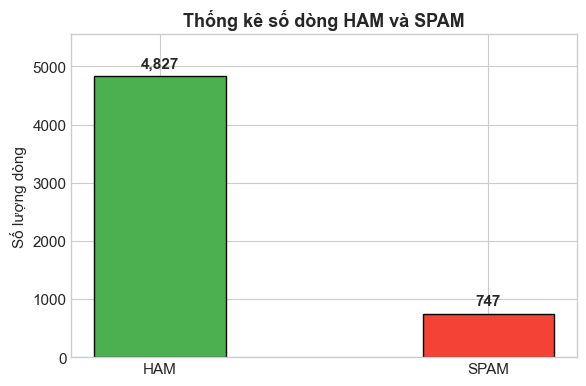

In [8]:
import matplotlib.pyplot as plt

file_path = "SMSSpamCollection"

total_lines = 0
spam_count = 0
ham_count = 0

with open(file_path, "r", encoding="utf-8") as f:
    for line in f:
        line_str = line.strip()
        if not line_str:
            continue
        total_lines += 1
        
        # Kiểm tra nhãn ở đầu dòng
        if line_str.startswith("spam\t") or line_str.startswith("spam "):
            spam_count += 1
        elif line_str.startswith("ham\t") or line_str.startswith("ham "):
            ham_count += 1

print(f"Tổng số dòng trong file: {total_lines:,} dòng")
print(f"Số dòng xuất hiện SPAM:  {spam_count:,} dòng")
print(f"Số dòng xuất hiện HAM:   {ham_count:,} dòng")

# Biểu đồ cột thể hiện số dòng
plt.figure(figsize=(6, 4))
bars = plt.bar(['HAM', 'SPAM'], [ham_count, spam_count], color=['#4CAF50', '#F44336'], width=0.4, edgecolor='black')
plt.title("Thống kê số dòng HAM và SPAM", fontweight='bold')
plt.ylabel("Số lượng dòng")
plt.ylim(0, max(ham_count, spam_count) * 1.15)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 100, f"{yval:,}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 2. Đếm số từ (ngăn cách bởi khoảng trắng, và không phải chữ số)


Tổng số từ trong file (không phải chữ số): 88,776 từ


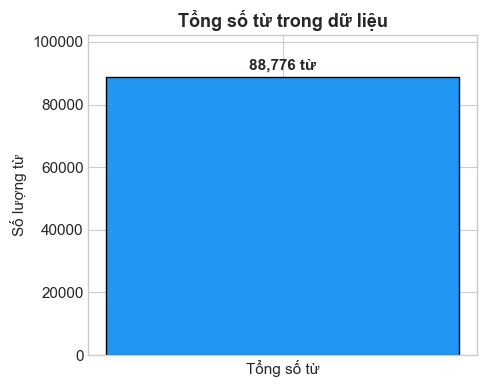

In [9]:
import re

words = []

with open(file_path, "r", encoding="utf-8") as f:
    for line in f:
        line_str = line.strip()
        if not line_str:
            continue
        
        # Tách từ bởi khoảng trắng
        tokens = line_str.split()
        for token in tokens:
            # Làm sạch dấu câu ở đầu và cuối từ, chuyển về chữ thường (không phân biệt hoa thường)
            w = re.sub(r"^\W+|\W+$", "", token).lower()
            # Kiểm tra từ không rỗng và không phải chữ số thuần túy
            if w and not w.isdigit():
                words.append(w)

total_words = len(words)
print(f"Tổng số từ trong file (không phải chữ số): {total_words:,} từ")

# Biểu đồ cột hiển thị tổng số từ
plt.figure(figsize=(5, 4))
bar = plt.bar(['Tổng số từ'], [total_words], color='#2196F3', width=0.3, edgecolor='black')
plt.title("Tổng số từ trong dữ liệu", fontweight='bold')
plt.ylabel("Số lượng từ")
plt.ylim(0, total_words * 1.15)
plt.text(bar[0].get_x() + bar[0].get_width()/2, total_words + 1500, f"{total_words:,} từ", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Đếm số từ 'you' (không phân biệt hoa thường)


Số từ 'you' xuất hiện trong file (không phân biệt hoa thường): 2,128 lần


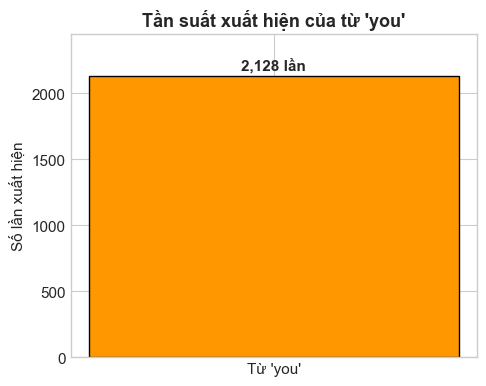

In [10]:
you_count = words.count("you")

print(f"Số từ 'you' xuất hiện trong file (không phân biệt hoa thường): {you_count:,} lần")

# Biểu đồ hiển thị số lần xuất hiện của từ 'you'
plt.figure(figsize=(5, 4))
bar = plt.bar(["Từ 'you'"], [you_count], color='#FF9800', width=0.3, edgecolor='black')
plt.title("Tần suất xuất hiện của từ 'you'", fontweight='bold')
plt.ylabel("Số lần xuất hiện")
plt.ylim(0, you_count * 1.15)
plt.text(bar[0].get_x() + bar[0].get_width()/2, you_count + 30, f"{you_count:,} lần", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Đếm số từ khác nhau (không phân biệt hoa thường)


Số từ khác nhau trong file (không phân biệt hoa thường): 9,266 từ duy nhất


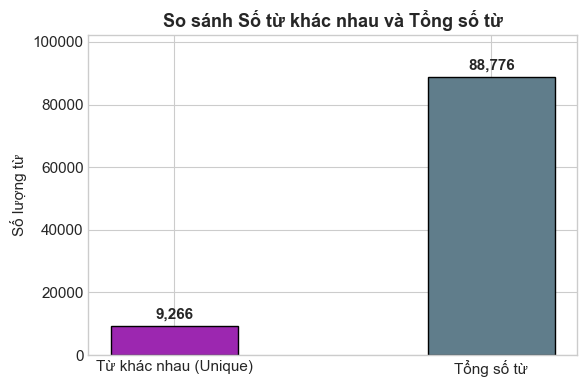

In [11]:
unique_words = set(words)
total_unique = len(unique_words)

print(f"Số từ khác nhau trong file (không phân biệt hoa thường): {total_unique:,} từ duy nhất")

# Biểu đồ hiển thị số từ khác nhau vs tổng số từ
plt.figure(figsize=(6, 4))
bars = plt.bar(['Từ khác nhau (Unique)', 'Tổng số từ'], [total_unique, total_words], color=['#9C27B0', '#607D8B'], width=0.4, edgecolor='black')
plt.title("So sánh Số từ khác nhau và Tổng số từ", fontweight='bold')
plt.ylabel("Số lượng từ")
plt.ylim(0, total_words * 1.15)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1500, f"{yval:,}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 5. Liệt kê 10 từ khóa xuất hiện nhiều nhất trong file dữ liệu (không phân biệt hoa thường)


=== TOP 10 TỪ KHÓA XUẤT HIỆN NHIỀU NHẤT ===
 1. Từ 'ham': 4,828 lần
 2. Từ 'to': 2,251 lần
 3. Từ 'i': 2,239 lần
 4. Từ 'you': 2,128 lần
 5. Từ 'a': 1,442 lần
 6. Từ 'the': 1,333 lần
 7. Từ 'u': 1,132 lần
 8. Từ 'and': 971 lần
 9. Từ 'is': 893 lần
10. Từ 'in': 888 lần


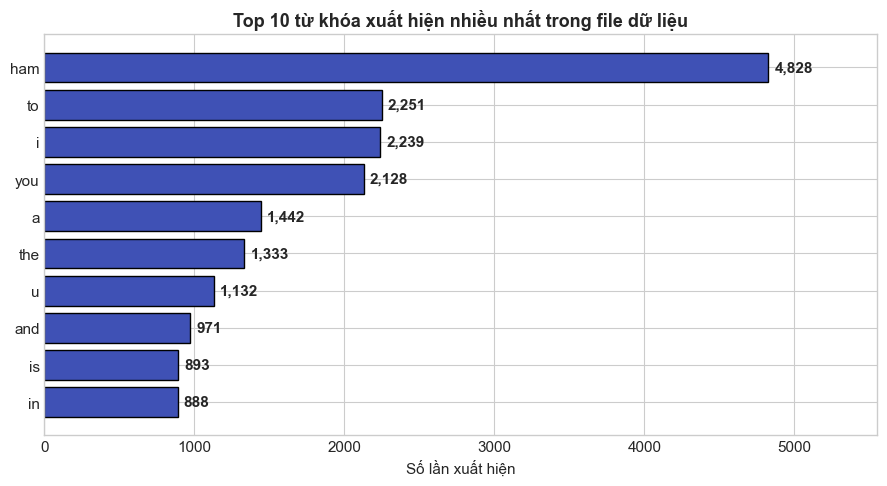

In [12]:
from collections import Counter

counter = Counter(words)
top10 = counter.most_common(10)

print("=== TOP 10 TỪ KHÓA XUẤT HIỆN NHIỀU NHẤT ===")
for i, (word, count) in enumerate(top10, 1):
    print(f"{i:>2}. Từ '{word}': {count:,} lần")

# Biểu đồ cột ngang Top 10 từ khóa
top10_words, top10_counts = zip(*top10[::-1])

plt.figure(figsize=(9, 5))
bars = plt.barh(top10_words, top10_counts, color='#3F51B5', edgecolor='black')
plt.title("Top 10 từ khóa xuất hiện nhiều nhất trong file dữ liệu", fontweight='bold')
plt.xlabel("Số lần xuất hiện")
plt.xlim(0, max(top10_counts) * 1.15)

for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 40, bar.get_y() + bar.get_height()/2, f"{xval:,}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()
